# Profile backtest: prediction error against reality (out-of-sample)

Measures the **actual** error of the seasonal profile: build `w_h` on week N, predict the hourly
traffic distribution for week N+1, and compare it with the actual N+1 distribution. This is the
out-of-sample error of precisely the component the balancer obtains from logs
(`build_seasonal_context` → `weights_dict`).

`w_h` (hourly volume shares) uses the same `_get_h_type`/`normalize_counts` logic as production.
The **volume** profile does NOT require `user_id`: only the time column is read, so running across
all weeks is inexpensive (no regexp on `path` and no `COUNT(DISTINCT)`).

**Metrics** (both use normalized shares, Σ=1 across hours):
- **TV (Total Variation distance)** = ½·Σ|pred−actual|: the share of traffic assigned to the **wrong hour** (headline metric).
- **WAPE (Weighted Absolute Percentage Error)** = Σ|pred−actual| = 2·TV: a standard forecasting metric.
- Baselines: `uniform` (no seasonality) and `climatology` (average of all previous weeks).

In [ ]:
import glob

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import production primitives for parity (hourly bucketing is duplicated in SQL below).
from rtb_sdk.balancer.seasonal.seasonality import _get_h_type, normalize_counts  # noqa: F401

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## Configuration

`PARQUET_FILES` contains weekly files **in chronological order** (a sorted glob by default).
`MODE`/`TIMEZONE` must match the production profile. `INCLUDE_REACH` enables a second,
expensive series: a backtest of the **reach** profile.

In [ ]:
MODE = "hour_of_day"          # or "hour_of_week"
TIMEZONE = "Europe/Moscow"    # as in build_seasonal_context (NOT DuckDB's UTC default)

# Weekly parquet files IN CHRONOLOGICAL ORDER (glob sorts by name;
# report-YYYYMMDD names sort by date). Alternatively, specify the list explicitly.
PARQUET_FILES = sorted(glob.glob("E:/Logs/report-*.parquet"))

# Also compute the reach profile (share of unique users) More expensive:
# requires regexp on path and COUNT(DISTINCT). The volume profile (w_h) does not
# depend on this. Enable deliberately.
INCLUDE_REACH = False

# DuckDB limits (as in the main notebook), relevant only for the expensive reach pass.
DUCKDB_THREADS = 4
DUCKDB_MEMORY_LIMIT = "8GB"
DUCKDB_TEMP_DIR = "E:/duckdb_tmp"

assert len(PARQUET_FILES) >= 2, (
    "At least 2 weekly files are required for a train-N / test-(N+1) backtest. "
    f"Found: {PARQUET_FILES}"
)
print(f"Files: {len(PARQUET_FILES)}")
for _f in PARQUET_FILES:
    print("  ", _f)

Files: 5
   E:/Logs\report-20260601.parquet
   E:/Logs\report-20260608.parquet
   E:/Logs\report-20260615.parquet
   E:/Logs\report-20260622.parquet
   E:/Logs\report-20260629.parquet


## Loading weekly hourly profiles

Compute normalized `w_h` (and optionally `reach_share_h`) for each week.

In [ ]:
_local_ts = "(datetime AT TIME ZONE '" + TIMEZONE + "')"
if MODE == "hour_of_week":
    HOUR_EXPR = ("((EXTRACT(dow FROM " + _local_ts + ") + 6) % 7) * 24 + "
                 "EXTRACT(hour FROM " + _local_ts + ")")
    N_H = 168
else:
    HOUR_EXPR = "EXTRACT(hour FROM " + _local_ts + ")"
    N_H = 24
# The client_id query parameter identifies a user.
USER_EXPR = ("COALESCE(NULLIF(regexp_extract('?' || split_part(path, '?', 2), "
             "'[?&]client_id=([^&]*)', 1), ''), 'EmptyUser')")

con = duckdb.connect()
con.execute(f"PRAGMA threads={DUCKDB_THREADS}")
con.execute(f"PRAGMA memory_limit='{DUCKDB_MEMORY_LIMIT}'")
con.execute(f"PRAGMA temp_directory='{DUCKDB_TEMP_DIR}'")


def week_label(path):
    return path.replace("\\", "/").split("/")[-1].rsplit(".", 1)[0]


def to_vec(agg):
    d = {int(h): float(c) for h, c in zip(agg["h"], agg["cnt"])}
    v = np.array([d.get(h, 0.0) for h in range(N_H)])
    return v / v.sum()


vol_profiles = {}    # label -> normalized w_h (np.array N_H)
reach_profiles = {}  # label -> normalized reach_share_h
meta = {}            # label -> (total, min_ts, max_ts)

for _f in PARQUET_FILES:
    label = week_label(_f)
    print(f"Volume profile: {label} ...", flush=True)
    # Only the datetime column: inexpensive scan without regexp on path.
    agg = con.execute(f"""
        SELECT {HOUR_EXPR} AS h, COUNT(*) AS cnt
        FROM read_parquet('{_f}')
        GROUP BY h ORDER BY h
    """).fetchdf()
    m = con.execute(f"""
        SELECT COUNT(*) AS t, MIN(datetime)::VARCHAR AS a, MAX(datetime)::VARCHAR AS b
        FROM read_parquet('{_f}')
    """).fetchone()
    vol_profiles[label] = to_vec(agg)
    meta[label] = (int(m[0]), m[1], m[2])

    if INCLUDE_REACH:
        print(f"Reach profile: {label} ... (expensive pass)", flush=True)
        ra = con.execute(f"""
            SELECT {HOUR_EXPR} AS h, COUNT(DISTINCT {USER_EXPR}) AS cnt
            FROM read_parquet('{_f}')
            GROUP BY h ORDER BY h
        """).fetchdf()
        reach_profiles[label] = to_vec(ra)

print("\nWeeks (in backtest order):")
for label in vol_profiles:
    t, a, b = meta[label]
    print(f"  {label}: {t:,} events, {a} -- {b}")

Volume profile: report-20260601 ...
Volume profile: report-20260608 ...
Volume profile: report-20260615 ...
Volume profile: report-20260622 ...
Volume profile: report-20260629 ...

Weeks (in backtest order):
  report-20260601: 104,032,996 events, 2026-06-01 03:00:00+03 -- 2026-06-08 02:59:59+03
  report-20260608: 237,938,183 events, 2026-06-08 03:00:00+03 -- 2026-06-15 02:59:59+03
  report-20260615: 154,418,448 events, 2026-06-15 03:00:00+03 -- 2026-06-22 02:59:59+03
  report-20260622: 172,638,062 events, 2026-06-22 03:00:00+03 -- 2026-06-29 02:59:59+03
  report-20260629: 40,758,905 events, 2026-06-29 03:00:00+03 -- 2026-07-01 02:59:59+03


## Weekly data-quality checks

Before backtesting, exclude weeks that would distort the result: incomplete periods
(less than 6.5 days), a spike in one hourly bucket (`peak_share > 4/N_H`, indicating a backfill
or duplicate load), and abnormal volume as an informational flag. The backtest below uses
only valid weeks.

In [ ]:
# === Data-quality guard: flag and exclude suspicious weeks ===================
# Three checks, each of which would reveal an issue in this dataset:
#   1. Period not approximately 7 days (incomplete week -> noisy profile).
#   2. One hourly bucket holds an implausible share (spike -> backfill/duplicate load;
#      this caused TV=0.47 with maxabs==TV in the pair involving report-20260608).
#   3. Volume differs greatly from the median (informational, supports check 2).
# Validity = passes (1) AND (2). Volume is only a warning.
from datetime import datetime as _dt

MIN_PERIOD_DAYS = 6.5          # a week must cover approximately 7 days
PEAK_RATIO_MAX = 4.0           # no hour should hold a share > PEAK_RATIO_MAX/N_H
VOL_DEVIATION_MAX = 0.6        # informational flag: |total/median - 1| exceeds this

totals = {lab: meta[lab][0] for lab in vol_profiles}
median_total = float(np.median(list(totals.values())))


def _span_days(lab):
    _, a, b = meta[lab]
    return (_dt.fromisoformat(b) - _dt.fromisoformat(a)).total_seconds() / 86400.0


quality = []
valid_labels = []
for lab in vol_profiles:
    prof = vol_profiles[lab]
    peak_share = float(prof.max())
    peak_h = int(prof.argmax())
    span = _span_days(lab)
    vol_ratio = totals[lab] / median_total if median_total else float("nan")

    bad_period = span < MIN_PERIOD_DAYS
    bad_peak = peak_share > PEAK_RATIO_MAX / N_H          # one dominant bucket
    vol_outlier = abs(vol_ratio - 1) > VOL_DEVIATION_MAX

    ok = not (bad_period or bad_peak)
    flags = []
    if bad_period:
        flags.append(f"incomplete period {span:.1f}d")
    if bad_peak:
        flags.append(f"spike at hour {peak_h} ({peak_share * 100:.1f}%)")
    if vol_outlier:
        flags.append(f"volume {vol_ratio:.2f}x median")
    quality.append({
        "week": lab, "period_days": round(span, 1), "volume": totals[lab],
        "vol_ratio": round(vol_ratio, 2), "peak_h": peak_h,
        "peak_share": round(peak_share, 4), "OK": ok,
        "flags": "; ".join(flags) or "-",
    })
    if ok:
        valid_labels.append(lab)

quality_df = pd.DataFrame(quality)
print(f"Valid weeks: {len(valid_labels)}/{len(vol_profiles)} -> {valid_labels}")
excluded = [q["week"] for q in quality if not q["OK"]]
if excluded:
    print(f"Excluded from backtest: {excluded}")
    print("The summary and pairs below use ONLY valid weeks.")
if len(valid_labels) < 2:
    print("[WARNING] fewer than 2 valid weeks: cannot backtest; more clean weeks are needed.")
quality_df

Valid weeks: 3/5 -> ['report-20260601', 'report-20260615', 'report-20260622']
Excluded from backtest: ['report-20260608', 'report-20260629']
The summary and pairs below use ONLY valid weeks.


,week,period_days,volume,vol_ratio,peak_h,peak_share,OK,flags
0,report-20260601,7.0,104032996,0.67,20,0.0613,True,-
1,report-20260608,7.0,237938183,1.54,12,0.5091,False,spike at hour 12 (50.9%)
2,report-20260615,7.0,154418448,1.00,23,0.0668,True,-
3,report-20260622,7.0,172638062,1.12,21,0.0594,True,-
4,report-20260629,2.0,40758905,0.26,22,0.0756,False,incomplete period 2.0d; volume 0.26x median


## Backtest: prediction vs reality

For each pair of consecutive weeks, prediction = the **previous** week's profile (`persistence`,
exactly what the balancer does), and reality = the current week's profile.

In [ ]:
from datetime import datetime as _dt2


def tv(pred, actual):
    return 0.5 * float(np.sum(np.abs(pred - actual)))


def wape(pred, actual):
    return float(np.sum(np.abs(pred - actual)))  # = 2 * tv


def maxabs(pred, actual):
    return float(np.max(np.abs(pred - actual)))


# Only valid weeks (see quality-check cell); fall back to all weeks.
try:
    labels = valid_labels
except NameError:
    labels = list(vol_profiles.keys())
uniform = np.full(N_H, 1.0 / N_H)


def _start(lab):
    return _dt2.fromisoformat(meta[lab][1])


rows = []
for i in range(1, len(labels)):
    train, test = labels[i - 1], labels[i]
    p_model = vol_profiles[train]                                   # persistence
    p_clim = np.mean([vol_profiles[labels[j]] for j in range(i)], axis=0)  # historical mean
    a = vol_profiles[test]                                          # actual
    gap_w = (_start(test) - _start(train)).total_seconds() / (7 * 86400)
    rows.append({
        "train": train, "test": test, "gap_weeks": round(gap_w, 1),
        "TV_model": tv(p_model, a),
        "TV_clim": tv(p_clim, a),
        "TV_uniform": tv(uniform, a),
        "WAPE_model": wape(p_model, a),
        "maxabs_model": maxabs(p_model, a),
    })

bt = pd.DataFrame(rows)
if len(bt):
    bt["gain_vs_uniform"] = (bt["TV_uniform"] - bt["TV_model"]) / bt["TV_uniform"]
bt

,train,test,gap_weeks,TV_model,TV_clim,TV_uniform,WAPE_model,maxabs_model,gain_vs_uniform
0,report-20260601,report-20260615,2.0,0.041733,0.041733,0.141545,0.083466,0.022247,0.705163
1,report-20260615,report-20260622,1.0,0.058124,0.048380,0.163083,0.116248,0.014566,0.643591


## Summary

In [ ]:
if not len(bt):
    print("No valid backtest pairs (see quality checks above).")
else:
    print(f"Valid weeks: {len(labels)}, train/test pairs: {len(bt)}")
    stale = bt[bt["gap_weeks"] > 1.0]
    if len(stale):
        print(f"[info] {len(stale)} pair(s) are nonconsecutive (gap > 1 week due to excluded "
              f"weeks): predictions are stale, so TV may be overstated.")
    print()
    print(f"TV_model  (profile error against reality): "
          f"mean={bt['TV_model'].mean():.4f}  "
          f"min={bt['TV_model'].min():.4f}  max={bt['TV_model'].max():.4f}")
    print(f"  => on average {bt['TV_model'].mean() * 100:.2f}% of traffic falls "
          f"OUTSIDE the predicted hour (WAPE={bt['WAPE_model'].mean() * 100:.2f}%)")
    print(f"TV_clim    (mean of all previous weeks): mean={bt['TV_clim'].mean():.4f}")
    print(f"TV_uniform (no seasonality):             mean={bt['TV_uniform'].mean():.4f}")
    print(f"\nThe profile beats uniform by {bt['gain_vs_uniform'].mean() * 100:.1f}% on average")
    if bt['TV_clim'].mean() < bt['TV_model'].mean():
        print("climatology (mean of previous weeks) is more accurate than persistence "
              "-> consider averaging weeks (EWMA, section 4 of the main document).")
    else:
        print("persistence (last week's profile) is no worse than averaging "
              "-> using the latest week is sufficient on clean data.")

Valid weeks: 3, train/test pairs: 2
[info] 1 pair(s) are nonconsecutive (gap > 1 week due to excluded weeks): predictions are stale, so TV may be overstated.

TV_model  (profile error against reality): mean=0.0499  min=0.0417  max=0.0581
  => on average 4.99% of traffic falls OUTSIDE the predicted hour (WAPE=9.99%)
TV_clim    (mean of all previous weeks): mean=0.0451
TV_uniform (no seasonality):              mean=0.1523

The profile beats uniform on average by 67.4%
climatology (mean of previous weeks) is more accurate than persistence -> consider averaging weeks (EWMA, section 4 of the main document).


## Chart: prediction vs reality

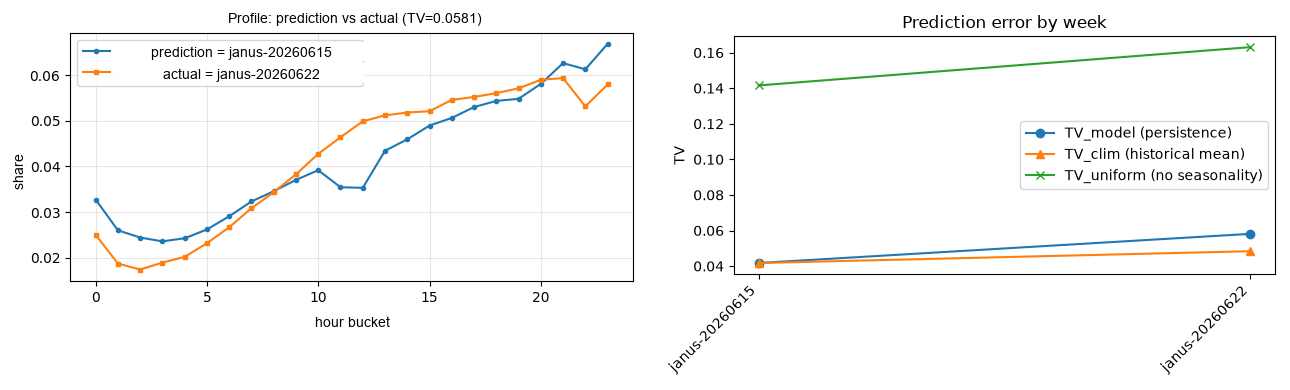

In [ ]:
if len(labels) < 2 or not len(bt):
    print("Not enough valid weeks to plot.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Left: predicted (latest train) vs actual (latest test) profile.
    tr, te = labels[-2], labels[-1]
    x = np.arange(N_H)
    axes[0].plot(x, vol_profiles[tr], marker="o", ms=3, label=f"prediction = {tr}")
    axes[0].plot(x, vol_profiles[te], marker="s", ms=3, label=f"actual = {te}")
    axes[0].set_title(f"Profile: prediction vs actual "
                      f"(TV={tv(vol_profiles[tr], vol_profiles[te]):.4f})")
    axes[0].set_xlabel("hour bucket")
    axes[0].set_ylabel("share")
    axes[0].legend()

    # Right: TV across weeks (model / climatology / uniform).
    xi = np.arange(len(bt))
    axes[1].plot(xi, bt["TV_model"], marker="o", label="TV_model (persistence)")
    axes[1].plot(xi, bt["TV_clim"], marker="^", label="TV_clim (historical mean)")
    axes[1].plot(xi, bt["TV_uniform"], marker="x", label="TV_uniform (no seasonality)")
    axes[1].set_xticks(xi)
    axes[1].set_xticklabels(bt["test"], rotation=45, ha="right")
    axes[1].set_title("Prediction error by week")
    axes[1].set_ylabel("TV")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## (Optional) Reach-profile backtest

Runs only if `INCLUDE_REACH = True`. Compares which profile predicts the following week
more consistently: the volume-based `w_h` or the reach-based `reach_share_h`.

In [ ]:
if INCLUDE_REACH and len(reach_profiles) >= 2:
    rlabels = list(reach_profiles.keys())
    rrows = []
    for i in range(1, len(rlabels)):
        p, a = reach_profiles[rlabels[i - 1]], reach_profiles[rlabels[i]]
        rrows.append({"train": rlabels[i - 1], "test": rlabels[i],
                      "TV_reach": tv(p, a)})
    rbt = pd.DataFrame(rrows)
    print(f"Reach profile out-of-sample TV: mean={rbt['TV_reach'].mean():.4f}")
    print(f"Volume w_h out-of-sample TV:    mean={bt['TV_model'].mean():.4f}")
    print("(lower => more consistent prediction of the following week)")
    display(rbt)
else:
    print("INCLUDE_REACH=False or fewer than 2 weeks: skipping reach backtest.")

INCLUDE_REACH=False or fewer than 2 weeks: skipping reach backtest.


## Interpretation

- **TV_model** is the actual out-of-sample error: the share of traffic assigned to the wrong hour
  when using the previous week's profile. It measures how much traffic the model mispredicts
  at the hourly-distribution level.
- **TV_uniform** is the same error without seasonality (uniform allocation).
  `TV_uniform − TV_model` is the value of the seasonal profile.
- **TV_clim** predicts using the average of all previous weeks instead of just the latest one.
  A value substantially below `TV_model` suggests averaging weeks (EWMA, section 4 of the
  main document) rather than using a single week.
- Some of `TV_model` is irreducible weekly sampling noise, not model error. A rough lower
  bound on noise can be estimated by comparing two halves of the SAME week.
- This measures **profile** error (hourly shape). Full per-ad balancer error requires ad_id and
  historical configurations — a separate experiment.